In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

In [2]:
def r_scatter(r):
    plots.figure(figsize=(5,5))
    "Generate a scatter plot with a correlation approximately r"
    x = np.random.normal(0, 1, 1000)
    z = np.random.normal(0, 1, 1000)
    y = r*x + (np.sqrt(1-r**2))*z
    plots.scatter(x, y, color='darkblue', s=20)
    plots.xlim(-4, 4)
    plots.ylim(-4, 4)

## Prediction ##

In [3]:
HighPeaks = Table.read_table('/home/jovyan/shared/Data/HighPeaks.csv')
HighPeaks

Peak,Elevation,Difficulty,Ascent,Length,Time
Mt. Marcy,5344,5,3166,14.8,10
Algonquin Peak,5114,5,2936,9.6,9
Mt. Haystack,4960,7,3570,17.8,12
Mt. Skylight,4926,7,4265,17.9,15
Whiteface Mtn.,4867,4,2535,10.4,8.5
Dix Mtn.,4857,5,2800,13.2,10
Gray Peak,4840,7,4178,16,14
Iroquois Peak,4840,6,3250,11.6,8.5
Basin Mtn.,4827,6,3650,16.5,11
Gothics,4736,5,4070,10,9


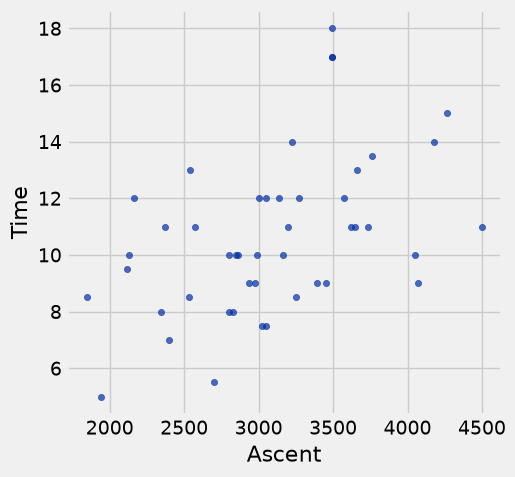

In [4]:
HighPeaks.scatter('Ascent', 'Time')

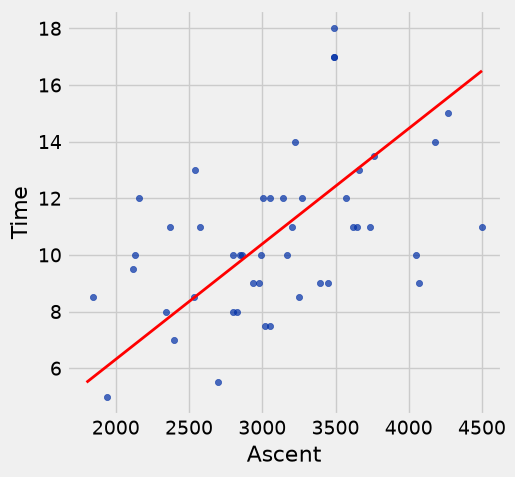

In [5]:
HighPeaks.scatter('Ascent', 'Time')

# My guess about a line that may describe the trend

plots.plot([1800,4500], [5.5,16.5], color='red', lw=2);

## Association ##

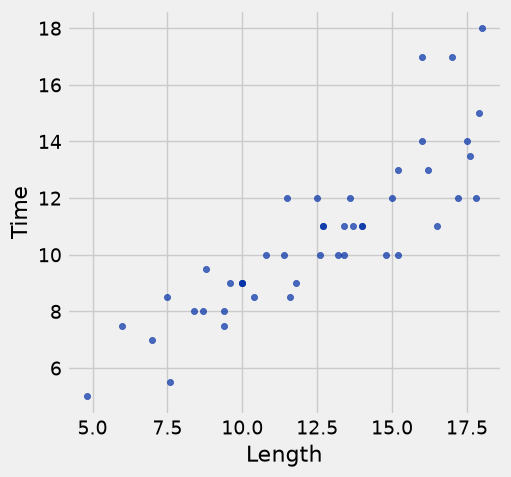

In [6]:
HighPeaks.scatter('Length', 'Time')

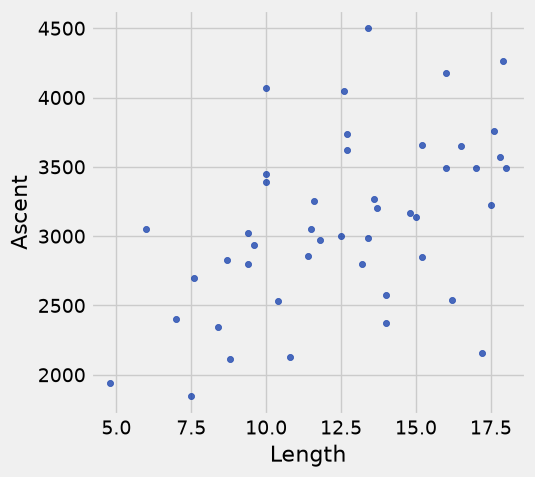

In [7]:
HighPeaks.scatter('Length', 'Ascent')

In [8]:
def standard_units(x):
    "Convert any array of numbers to standard units."
    return (x - np.average(x)) / np.std(x)

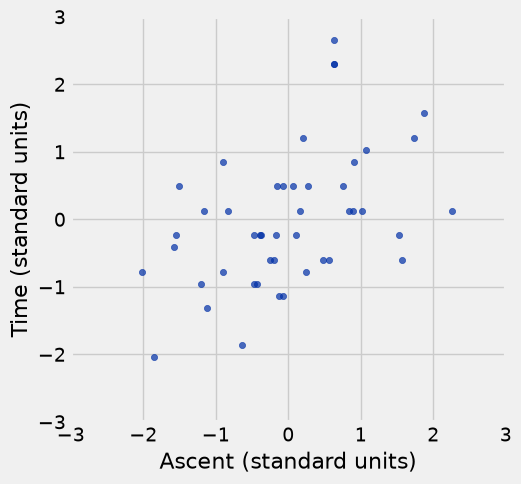

In [9]:
Table().with_columns(
    'Ascent (standard units)',  standard_units(HighPeaks.column('Ascent')), 
    'Time (standard units)', standard_units(HighPeaks.column('Time'))
).scatter(0, 1)

plots.xlim(-3, 3)
plots.ylim(-3, 3);

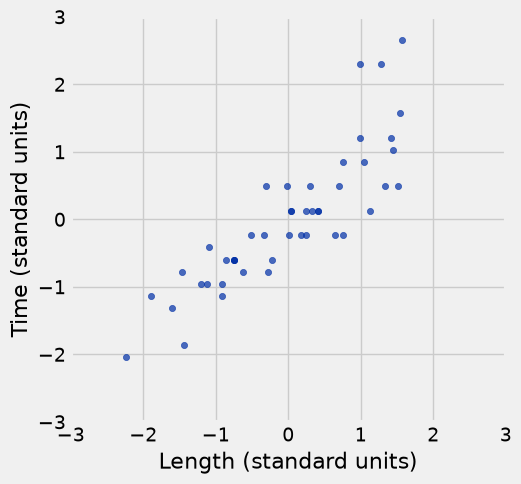

In [10]:
Table().with_columns(
    'Length (standard units)',  standard_units(HighPeaks.column('Length')), 
    'Time (standard units)', standard_units(HighPeaks.column('Time'))
).scatter(0, 1)

plots.xlim(-3, 3)
plots.ylim(-3, 3);

## Correlation ##

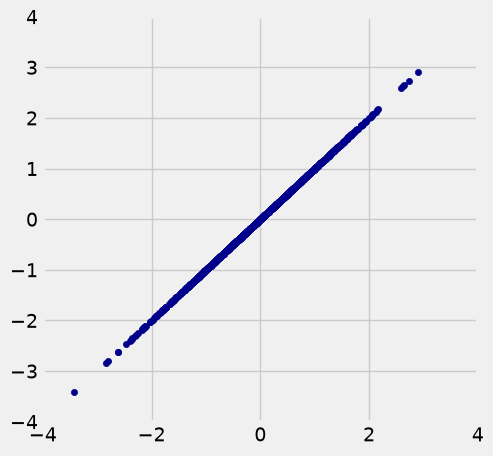

In [11]:
r_scatter(1)

In [ ]:
r_scatter(0.66)

In [ ]:
r_scatter(0.33)

In [ ]:
r_scatter(0)

In [ ]:
r_scatter(-0.33)

In [ ]:
r_scatter(-0.66)

In [ ]:
r_scatter(-1)

## Calculating $r$ ##

In [ ]:
HighPeaks_AT = HighPeaks.select('Ascent', 'Time')
HighPeaks_AT

In [ ]:
HighPeaks_AT.scatter('Ascent')

In [ ]:
HighPeaks_AT = HighPeaks_AT.with_columns(
    'Ascent (standard units)',  standard_units(HighPeaks.column('Ascent')), 
    'Time (standard units)', standard_units(HighPeaks.column('Time'))
)

HighPeaks_AT

In [ ]:
HighPeaks_AT = HighPeaks_AT.with_columns(
    'product of standard units', HighPeaks_AT.column(2) * HighPeaks_AT.column(3))
HighPeaks_AT

In [ ]:
# r is the average of the products of the standard units

r = np.average(HighPeaks_AT.column(2) * HighPeaks_AT.column(3))
r

## Function for Calculating $r$ ##

In [ ]:
def correlation(t, x, y):
    """t is a table; x and y are column labels"""
    x_in_standard_units = standard_units(t.column(x))
    y_in_standard_units = standard_units(t.column(y))
    return np.average(x_in_standard_units * y_in_standard_units)

In [ ]:
correlation(HighPeaks, 'Ascent', 'Time')

In [ ]:
correlation(HighPeaks, 'Length', 'Time')

In [ ]:
correlation(HighPeaks, 'Length', 'Ascent')

### Switching Axes ###

In [ ]:
correlation(HighPeaks, 'Ascent', 'Time'), correlation(HighPeaks, 'Time', 'Ascent')

### Nonlinearity ###

In [ ]:
health = Table.read_table('/home/jovyan/shared/Data/health.csv')
health

In [ ]:
correlation(health, 'age', 'bmi')

In [ ]:
health.scatter('age', 'bmi')

### Outliers ###

In [ ]:
PalmBeach = Table.read_table('/home/jovyan/shared/Data/PalmBeach.csv')
PalmBeach

In [ ]:
correlation(PalmBeach, 'Buchanan', 'Bush')

In [ ]:
PalmBeach.scatter('Bush', 'Buchanan')
plots.xticks(rotation = 270);

In [ ]:
PalmBeach_removed = PalmBeach.where('County', are.not_containing('PALM BEACH'))

In [ ]:
PalmBeach_removed.scatter('Bush', 'Buchanan')
plots.xticks(rotation = 270);

In [ ]:
correlation(PalmBeach_removed, 'Buchanan', 'Bush')